# NWC attribution: four validation-selected models

Stage 09 reads the verified Stage 08 raw test predictions. Each track uses its validation-selected feature group, algorithm and parameters: W1 uses RW / XGBoost, W2 uses RBW / HistGradientBoosting, M1 uses IBW / Logistic Regression, and M2 uses IBW / Random Forest. Selection uses validation event Log Loss only. Stage 09 performs no training, model selection, calibration fitting or new predictions. Coverage is the Stage 08 test cohort, not all historical matches.

Complete interval accounting; PARTIAL rule-based player allocation plus explicit team residuals. The first-innings final event and innings transition remain an inseparable, jointly unallocated bundle. No synthetic post-event predictions or causal player effects are claimed.

Reports and ledgers use `resource_sums_v2_joint_selection_v1` subdirectories. The manifest verifies the source predictions and attribution outputs. See `docs/current_workflow.md` for execution controls and `docs/stage09_joint_selection_protocol.md` for the method specification.


In [57]:
from pathlib import Path
import sys
import json
import importlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if not (ROOT / 'src/nwc_attribution_joint.py').is_file():
    raise RuntimeError('Open the project root or its notebooks folder.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
import nwc_attribution_joint as stage
import nwc_attribution_joint_visualisation as viz
importlib.reload(stage)
importlib.reload(viz)
RUN_ATTRIBUTION = False
SAVE_FIGURES = True
SAVE_TERMINAL_AUDIT = False  # True exports diagnostics only; never changes attribution.
EXAMPLE_MATCH_ID = None  # None selects the earliest test date, then match ID; never select by results.
OUTPUT = ROOT / stage.REPORT_DIR

print('Project:', ROOT)
print('Python:', sys.executable)
print('Four validation-selected Stage 08 models; rule-based partial player allocation; no fitting or prediction.')


Project: d:\T20_Project\T20_Project_3.0
Python: d:\T20_Project\T20_Project_3.0\.venv\Scripts\python.exe
Four validation-selected Stage 08 models; rule-based partial player allocation; no fitting or prediction.


## 09.1 Frozen protocol and explicit execution

Probability always refers to the first-innings batting team. Within an innings the ledger measures the observed interval from the current pre-event state to the next pre-event state. Ordinary no-extra/no-exit intervals use the CURRENT-event striker/bowler zero-sum proxy. Strike swaps, batting-pair changes and next-bowler changes are flagged but do not automatically exclude the interval. This does not separate the effects of personnel changes from the event.

Bowled/LBW without extras use the pair proxy only when the dismissed striker and wicket count match the source. Other exits, fielding-assisted events, extras, penalties and unidentified first-innings endpoints remain team residuals. These are project accounting conventions, not official scorebook NWC or causal responsibility.

The audited terminal endpoint is 0 or 1. The final event is kept in full without clipping or smoothing. If it qualifies for the allocation proxy, its player contribution is reported separately as well. Terminal closure applies only to the attribution ledger, not to the raw model probabilities or Stage 08 evaluation scores. Post-innings penalties remain unallocated.


In [58]:
if RUN_ATTRIBUTION:
    stage.run(ROOT)
summary = stage.verified_output(ROOT)
print('Verified attribution:', summary['attribution_id'])
print('Contract:', summary['contract_version'], '| Stage 08:', summary['upstream_evaluation_id'])
print('Matches:', summary['matches'], '| Recorded events:', summary['events'])
print('Allocated events:', summary['allocated_events'], '| Unallocated events:', summary['unallocated_events'])
print('Player allocation coverage:', f"{summary['allocation_coverage']:.1%}")
print('Allocated intervals with role changes:', summary['allocated_role_change_events'])
print('Player allocation uses explicit accounting rules. Coverage does not establish causal validity.')
print('Output status:', summary['player_output_status'])
print('Training fits:', summary['training_fits'], '| Prediction calls:', summary['prediction_calls'])
protocol = json.loads((OUTPUT / 'attribution_protocol.json').read_text(encoding='utf-8'))
display(pd.DataFrame(protocol['handoff']['preferred_models'])[['track', 'arm_code', 'family']])
display(pd.read_csv(OUTPUT / 'allocation_rules.csv'))


Verified attribution: f6a25bf2480b950fe31e69672273d7a4c06807f72e6efce1098ba6261d48baae
Contract: resource_sums_v2_joint_selection_v1 | Stage 08: 31bd1c42bb6e0ec84f9824da5fe496de9fc7e0680f32c96bc2db445e30fa3bea
Matches: 228 | Recorded events: 53850
Allocated events: 48469 | Unallocated events: 5381
Player allocation coverage: 90.0%
Allocated intervals with role changes: 24225
Player allocation uses explicit accounting rules. Coverage does not establish causal validity.
Output status: rule_based_interval_NWC_with_team_residuals_not_causal
Training fits: 0 | Prediction calls: 0


,track,arm_code,family
0,female_innings_1,RW,xgboost
1,female_innings_2,RBW,hist_gradient_boosting
2,male_innings_1,IBW,logistic_regression
3,male_innings_2,IBW,random_forest


,case,destination,convention
0,first_innings_boundary,team,First-innings last event plus transition; endp...
1,post_innings_penalty,team,Terminal/boundary interval includes a post-inn...
2,penalty_event,team,Do not infer individual responsibility from a ...
3,extras_and_exit,team,Do not divide a mixed interval by runs or gues...
4,wide_or_no_ball,team,Whole interval retained at team level; no auto...
5,bye_or_legbye,team,No individual batting/bowling split inferred.
6,bowled_or_lbw_without_extras,player_pair,Current striker and bowler receive opposite in...
7,run_out,team,Do not force a non-striker or fielding event o...
8,caught_caught_and_bowled_stumped,team,Fielding/exit interval not individually decomp...
9,other_exit_or_retirement,team,No personal retirement/responsibility inference.


## 09.2 Coverage and accounting checks

Every recorded event, including each innings' first event, appears exactly once. All first-innings final-event effects remain unidentified individually, but are present in the boundary bundles. Whole-match closure includes allocated intervals, unallocated intervals and those bundles. This is a bookkeeping identity, not evidence that allocation is causally correct.


In [59]:
coverage = pd.read_csv(OUTPUT / 'allocation_coverage.csv')
reconciliation = pd.read_csv(OUTPUT / 'match_reconciliation.csv')
display(coverage)
display(reconciliation.head(10))
display(pd.read_csv(OUTPUT / 'team_reconciliation.csv').head(10))
print('Maximum team/player accounting error:', summary['max_team_closure_error'])
print('Maximum reconciliation error:', reconciliation.closure_error.max())
print('Recorded innings-first events:', summary['first_events_recorded'])
print('Unseparated first-innings endpoint bundles:', summary['boundary_bundles'])
print('Audited terminal events:', summary['terminal_events'])


,track,allocation_reason,events,first_team_wpa,absolute_wpa,track_event_fraction
0,female_innings_1,player_direct_dismissal_proxy,132,-3.181407,3.556470,0.012195
1,female_innings_1,player_ordinary_interval_proxy,9669,19.232591,105.895695,0.893293
2,female_innings_1,team_bye_or_legbye_interval,144,0.473385,0.920430,0.013304
3,female_innings_1,team_fielding_exit_not_decomposed,332,-6.292284,7.078002,0.030673
4,female_innings_1,team_first_innings_boundary,87,6.724847,15.804907,0.008038
5,female_innings_1,team_mixed_extras_and_exit,2,0.008786,0.008786,0.000185
6,female_innings_1,team_other_exit_or_retirement,2,-0.003819,0.005558,0.000185
7,female_innings_1,team_run_out_shared_responsibility,40,-0.831629,0.839768,0.003695
8,female_innings_1,team_wide_or_no_ball_interval,416,5.323168,5.673612,0.038433
9,female_innings_2,player_direct_dismissal_proxy,129,3.278913,4.008648,0.013183


,match_id,gender,match_date,events,allocated_events,unallocated_events,start_probability,outcome,probability_change,allocated_first_team_wpa,unallocated_first_team_wpa,boundary_bundle,terminal_wpa,closure_error
0,1432211,male,2024-12-10,251,224,27,0.444125,1,0.555875,0.380868,0.175007,0.242526,0.036821,5.551115e-17
1,1432212,male,2024-12-13,255,227,28,0.431458,0,-0.431458,-0.238347,-0.193111,-0.087844,-0.048462,0.000000e+00
2,1433383,male,2024-12-15,251,222,29,0.334497,1,0.665503,0.390011,0.275492,-0.079575,0.057206,1.110223e-16
3,1433384,male,2024-12-17,239,216,23,0.352206,1,0.647794,0.259168,0.388626,0.016031,0.019107,5.551115e-17
4,1433385,male,2024-12-19,228,202,26,0.414621,1,0.585379,0.793945,-0.208566,0.093019,0.000126,0.000000e+00
5,1439899,male,2025-01-22,203,181,22,0.455243,0,-0.455243,-0.165851,-0.289392,0.018696,-0.033499,0.000000e+00
6,1439900,male,2025-01-25,243,221,22,0.445933,0,-0.445933,-0.329045,-0.116888,0.176945,-0.282021,5.551115e-17
7,1439901,male,2025-01-28,251,222,29,0.408008,1,0.591992,0.478704,0.113288,0.238195,0.009975,1.110223e-16
8,1439903,male,2025-02-02,188,162,26,0.659272,1,0.340728,0.272398,0.068331,-0.116715,0.019036,0.000000e+00
9,1443543,male,2024-12-28,250,223,27,0.601136,1,0.398864,0.095863,0.303001,0.175917,0.038197,1.110223e-16


,match_id,team,player_interval_total,team_residual,expected_probability_change,closure_error
0,1432211,South Africa,0.380868,0.175007,0.555875,0.000000e+00
1,1432211,Pakistan,-0.380868,-0.175007,-0.555875,0.000000e+00
2,1432212,Pakistan,-0.238347,-0.193111,-0.431458,0.000000e+00
3,1432212,South Africa,0.238347,0.193111,0.431458,0.000000e+00
4,1433383,Bangladesh,0.390011,0.275492,0.665503,1.110223e-16
5,1433383,West Indies,-0.390011,-0.275492,-0.665503,1.110223e-16
6,1433384,Bangladesh,0.259168,0.388626,0.647794,0.000000e+00
7,1433384,West Indies,-0.259168,-0.388626,-0.647794,0.000000e+00
8,1433385,Bangladesh,0.793945,-0.208566,0.585379,0.000000e+00
9,1433385,West Indies,-0.793945,0.208566,-0.585379,0.000000e+00


Maximum team/player accounting error: 3.3306690738754696e-16
Maximum reconciliation error: 3.8857805861880484e-16
Recorded innings-first events: 456
Unseparated first-innings endpoint bundles: 228
Audited terminal events: 228


## 09.3 Terminal events and first-innings boundary bundles

A large terminal change may reflect a genuinely decisive event or a poor pre-event prediction. These cannot be separated just by forcing a synthetic terminal model prediction. The boundary table combines the first-innings last event, any intervening updates and the innings-model transition; it must not be reported as a pure calibration error or pure innings gap.


In [60]:
terminal = pd.read_csv(OUTPUT / 'terminal_events.csv')
boundaries = pd.read_csv(OUTPUT / 'boundary_bundles.csv')
display(terminal.sort_values('absolute_terminal_wpa', ascending=False)[['match_id', 'track', 'probability_before', 'interval_endpoint_probability', 'terminal_first_team_wpa', 'allocation_reason']].head(12))
display(boundaries[['match_id', 'track', 'probability_before', 'interval_endpoint_probability', 'boundary_bundle_first_team', 'allocation_reason']].head(12))


,match_id,track,probability_before,interval_endpoint_probability,terminal_first_team_wpa,allocation_reason
51,1476993,female_innings_2,0.994532,0.0,-0.994532,player_ordinary_interval_proxy
43,1472526,male_innings_2,0.937298,0.0,-0.937298,player_ordinary_interval_proxy
55,1477597,female_innings_2,0.813866,0.0,-0.813866,player_ordinary_interval_proxy
66,1478900,male_innings_2,0.759493,0.0,-0.759493,player_ordinary_interval_proxy
221,1538303,male_innings_2,0.350813,0.0,-0.350813,player_ordinary_interval_proxy
20,1444654,male_innings_2,0.320490,0.0,-0.320490,player_ordinary_interval_proxy
6,1439900,male_innings_2,0.282021,0.0,-0.282021,player_ordinary_interval_proxy
176,1512763,male_innings_2,0.262996,0.0,-0.262996,player_ordinary_interval_proxy
38,1472520,male_innings_2,0.236450,0.0,-0.236450,player_ordinary_interval_proxy
41,1472523,male_innings_2,0.228446,0.0,-0.228446,player_ordinary_interval_proxy


,match_id,track,probability_before,interval_endpoint_probability,boundary_bundle_first_team,allocation_reason
0,1432211,male_innings_1,0.462563,0.705089,0.242526,team_first_innings_boundary
1,1432212,male_innings_1,0.787187,0.699343,-0.087844,team_first_innings_boundary
2,1433383,male_innings_1,0.322340,0.242764,-0.079575,team_first_innings_boundary
3,1433384,male_innings_1,0.189496,0.205527,0.016031,team_first_innings_boundary
4,1433385,male_innings_1,0.665955,0.758974,0.093019,team_first_innings_boundary
5,1439899,male_innings_1,0.105380,0.124076,0.018696,team_first_innings_boundary
6,1439900,male_innings_1,0.254401,0.431347,0.176945,team_first_innings_boundary
7,1439901,male_innings_1,0.286349,0.524544,0.238195,team_first_innings_boundary
8,1439903,male_innings_1,0.943816,0.827101,-0.116715,team_first_innings_boundary
9,1443543,male_innings_1,0.589138,0.765056,0.175917,team_first_innings_boundary


## 09.4 Probability curves, interval changes and partial player contributions

The nominal 120-slot view is a display clock only. Extras share positions and audited over-count exceptions can share the capped boundary position. The recorded-event view retains every event separately. No first-innings post-event point is invented and no line joins the two innings as if it were a delivery. Terminal closure is dotted and separately marked.

Player rows are alphabetical, not an ability ranking. Three panels on the same scale show non-terminal contribution, terminal contribution and their total. Each row shows allocated/observed role-event counts. Missing contribution means no allocated observations, not measured zero. The non-terminal subtotal is a decomposition, not a replacement score.

Cumulative individual contributions may exceed 100 percentage points in magnitude. They sum selected intervals rather than represent a single win probability; other players or team residuals can offset them. Totals are not capped or rescaled.


match_probability_120


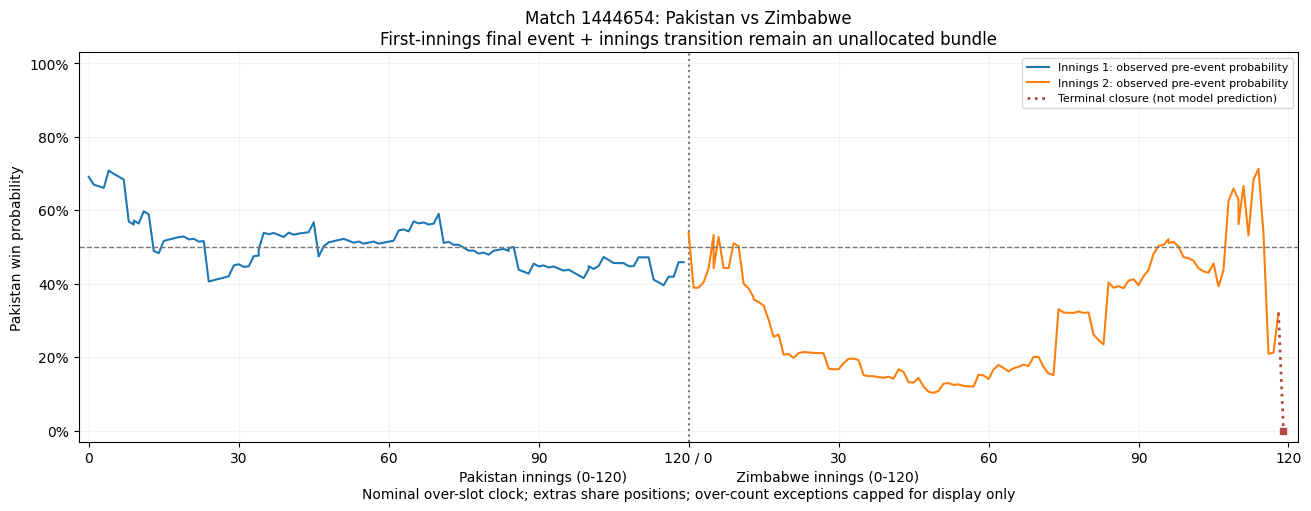

match_probability_events


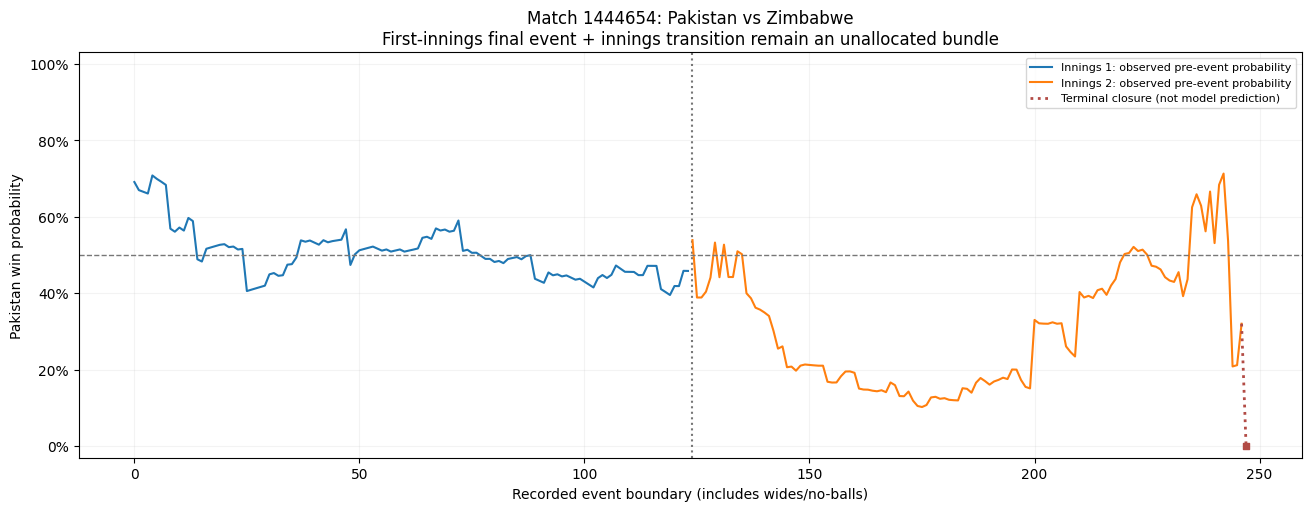

match_interval_changes


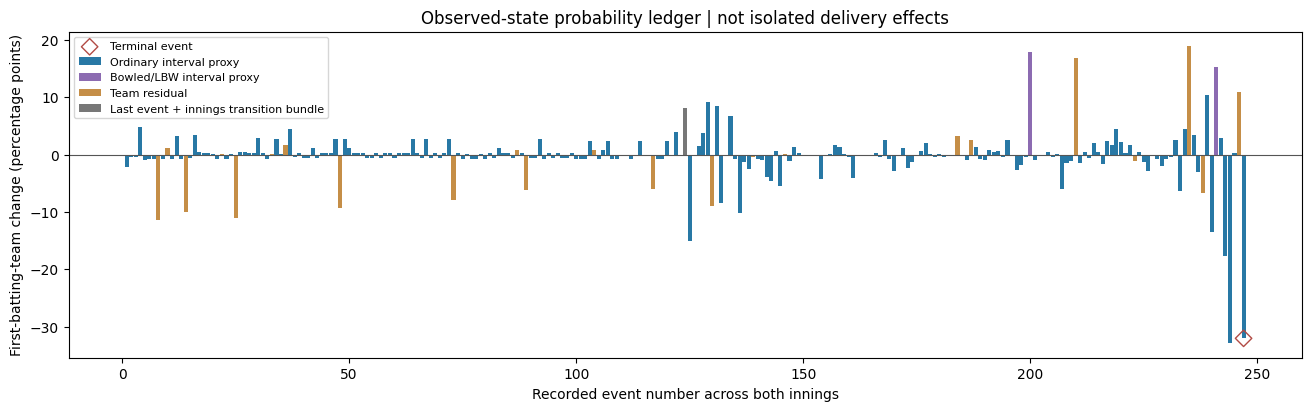

player_partial_contributions


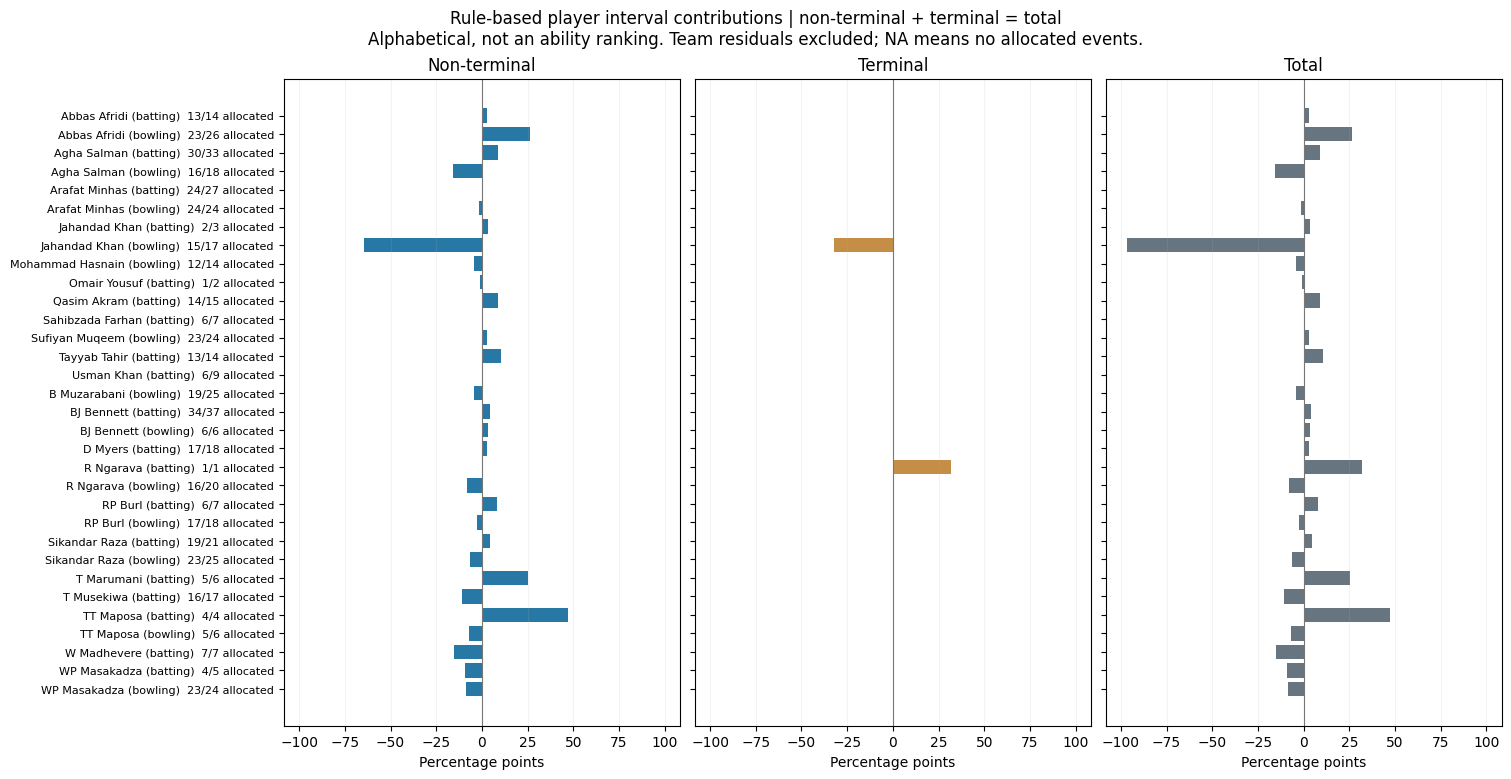

allocation_coverage


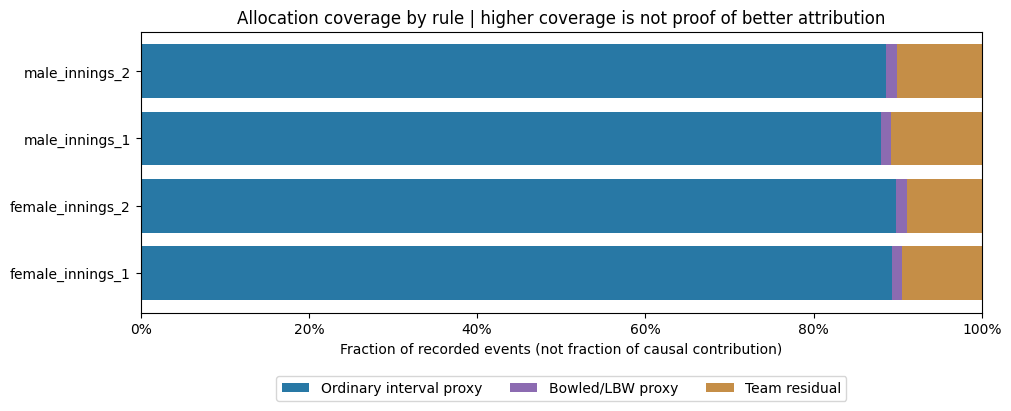

terminal_changes


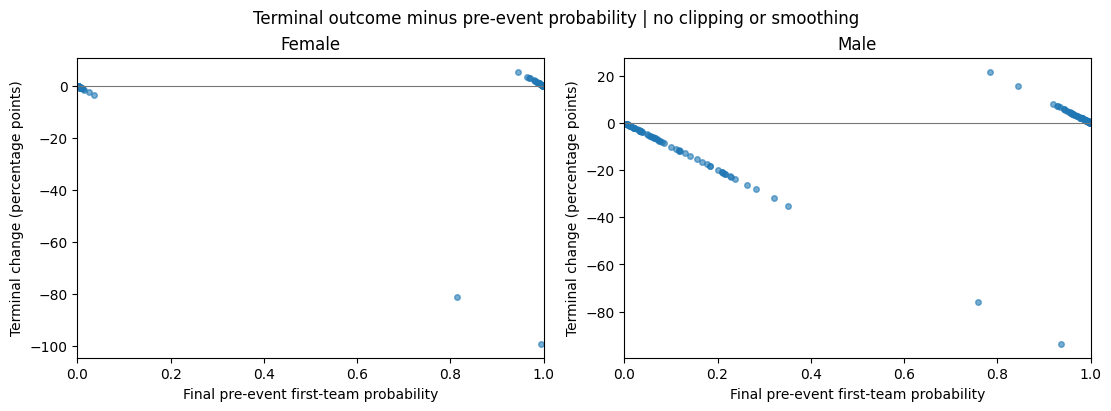

In [61]:
figures = viz.build_figures(ROOT, EXAMPLE_MATCH_ID)
if SAVE_FIGURES:
    viz.save_figures(ROOT, summary, figures)
for name, figure in figures.items():
    print(name)
    display(figure)
plt.close('all')


## 09.5 Player table and interpretation limits

Do not compare totals without considering selective allocation coverage. Both batting and bowling entries are operational accounting proxies. Bowled/LBW use a restricted pair convention; other exits, extras and the first-innings boundary remain team residuals. Role changes are retained and flagged rather than treated as isolated delivery effects. A complete individual NWC method requires an additional justified post-state/attribution design; this notebook does not claim to solve that identification problem.


In [62]:
players = pd.read_csv(OUTPUT / 'player_match_partial_nwc.csv')
display(players.head(20))
for limitation in summary['limitations']:
    print('-', limitation)


,match_id,gender,team,player_id,player,role,role_events,allocated_events,unallocated_events,partial_nwc,terminal_partial_nwc,role_change_allocated_events,ordinary_proxy_events,direct_dismissal_proxy_events,terminal_allocated_events,allocation_coverage,partial_nwc_excluding_terminal
0,1432211,male,Pakistan,24bb1c2f,Haris Rauf,batting,3,3,0,-0.082258,-0.036821,2,3,0,1,1.000000,-0.045437
1,1432211,male,Pakistan,24bb1c2f,Haris Rauf,bowling,25,24,1,-0.162304,0.000000,12,24,0,0,0.960000,-0.162304
2,1432211,male,Pakistan,2cec2a92,Abbas Afridi,batting,1,1,0,-0.059093,0.000000,1,0,1,0,1.000000,-0.059093
3,1432211,male,Pakistan,2cec2a92,Abbas Afridi,bowling,24,22,2,-0.103906,0.000000,8,22,0,0,0.916667,-0.103906
4,1432211,male,Pakistan,2f26ac1a,Mohammad Rizwan,batting,65,55,10,0.117537,0.000000,29,55,0,0,0.846154,0.117537
5,1432211,male,Pakistan,33609a8c,Saim Ayub,batting,15,14,1,0.078506,0.000000,5,14,0,0,0.933333,0.078506
6,1432211,male,Pakistan,4277234d,Sufiyan Muqeem,batting,3,3,0,0.005315,0.000000,1,3,0,0,1.000000,0.005315
7,1432211,male,Pakistan,4277234d,Sufiyan Muqeem,bowling,24,23,1,-0.243516,0.000000,8,23,0,0,0.958333,-0.243516
8,1432211,male,Pakistan,431f8af4,Tayyab Tahir,batting,20,17,3,-0.019554,0.000000,8,17,0,0,0.850000,-0.019554
9,1432211,male,Pakistan,45a7e761,Shaheen Shah Afridi,batting,8,6,2,0.023870,0.000000,3,6,0,0,0.750000,0.023870


- PARTIAL operational player allocation, not complete player NWC or causal player value.
- Next-pre-event probabilities contain observed intervening state updates, not isolated ball effects.
- First-innings last-event effect and innings transition are inseparable and jointly unallocated.
- Role changes are flagged, not excluded: their effects are not separated from event-interval changes.
- Ordinary no-extra/no-exit intervals and validated bowled/LBW intervals use the current-event striker/bowler convention.
- Other exits, extras and post-innings penalties stay in team residuals, without guessed individual responsibility.
- Player allocation is a bookkeeping convention, not identified responsibility or official scorebook NWC.
- Allocation coverage does not establish causal accuracy.
- Terminal WPA can be large because of genuine uncertainty or model error; it is neither clipped nor smoothed.
- No terminal post-state model probability is fabricated, and no causal closure-error decomposi

## 09.6 Terminal case audit (read-only diagnostics)

Inspect all matches with absolute terminal WPA >= 25 percentage points. Determine the selected-case count from the current verified probabilities rather than a hardcoded count. Recheck raw JSON delivery facts, pre-event state, target, audited ending and winner against the saved ledger and frozen Stage 08 probabilities. The last five recorded events are context only, never smoothing or redistribution of terminal contribution.

All probability columns explicitly identify first batting team or chasing team. Remaining legal balls use retrospective source-audited over lengths only for diagnosis. Passing these checks establishes source/accounting consistency, NOT probability calibration or causal attribution. Outcome-selected cases must not be used to tune models.

The following cells inspect without fitting, predicting or regenerating attribution. `SAVE_TERMINAL_AUDIT = True` additionally exports the diagnostics in the versioned terminal_case_audit directory. Keep `RUN_ATTRIBUTION = False` when only reviewing results.


In [63]:
import nwc_terminal_audit_joint as terminal_audit
importlib.reload(terminal_audit)
terminal_cases, terminal_context, terminal_summary = (
    terminal_audit.export(ROOT) if SAVE_TERMINAL_AUDIT else terminal_audit.inspect(ROOT)
)
print('Terminal cases:', terminal_summary['selected_cases'], '| Passed:', terminal_summary['passed_cases'], '| Failed:', terminal_summary['failed_cases'])
print('Training fits: 0 | New predictions: 0 | Attribution changes: 0')
display(terminal_cases[['match_id', 'gender', 'first_batting_team', 'chasing_team', 'pre_score', 'pre_wickets', 'target', 'runs_needed', 'audited_scheduled_legal_balls_remaining', 'final_event_runs', 'final_event_exit', 'completion_basis', 'first_team_probability_pct', 'chasing_team_probability_pct', 'terminal_change_pp', 'all_checks_pass']].round(3) if not terminal_cases.empty else terminal_cases)
if terminal_summary['failed_cases']:
    display(terminal_cases.loc[~terminal_cases.all_checks_pass, ['match_id', 'failed_checks', 'source_issues']])
else:
    print('No selected-case source/accounting mismatch detected. This does not certify the model probabilities.')


Terminal cases: 8 | Passed: 8 | Failed: 0
Training fits: 0 | New predictions: 0 | Attribution changes: 0


,match_id,gender,first_batting_team,chasing_team,pre_score,pre_wickets,target,runs_needed,audited_scheduled_legal_balls_remaining,final_event_runs,final_event_exit,completion_basis,first_team_probability_pct,chasing_team_probability_pct,terminal_change_pp,all_checks_pass
0,1476993,female,Pakistan,Ireland,165,6,169,4,1,6,,target_reached,99.453,0.547,-99.453,True
1,1472526,male,Pakistan,West Indies,131,8,134,3,1,4,,target_reached,93.730,6.270,-93.730,True
2,1477597,female,Pakistan,South Africa,179,5,181,2,1,6,,target_reached,81.387,18.613,-81.387,True
3,1478900,male,South Africa,Australia,169,8,173,4,2,4,,target_reached,75.949,24.051,-75.949,True
4,1538303,male,Zimbabwe,Bangladesh,140,6,144,4,3,4,,target_reached,35.081,64.919,-35.081,True
5,1444654,male,Pakistan,Zimbabwe,132,8,133,1,2,1,,target_reached,32.049,67.951,-32.049,True
6,1439900,male,England,India,162,8,166,4,5,4,,target_reached,28.202,71.798,-28.202,True
7,1512763,male,Pakistan,England,162,8,165,3,6,4,,target_reached,26.300,73.700,-26.300,True


No selected-case source/accounting mismatch detected. This does not certify the model probabilities.


In [64]:
for match_id, context in terminal_context.groupby('match_id', sort=False):
    print('Match', match_id, '| Last five recorded events | Probability: FIRST batting team')
    display(context.round(4))
for limitation in terminal_summary['limitations']:
    print('-', limitation)


Match 1439900 | Last five recorded events | Probability: FIRST batting team


,match_id,event_sequence,pre_score,pre_wickets,legal_balls_elapsed,target_runs,striker,bowler,runs_total,wicket_kind,raw_model_probability,interval_endpoint_probability,interval_wpa_first_team,is_terminal_event
1665,1439900,118,155,8,111,166.0,Tilak Varma,LS Livingstone,1,NaN,0.3486,0.3588,0.0102,False
1666,1439900,119,156,8,112,166.0,Ravi Bishnoi,LS Livingstone,4,NaN,0.3588,0.2931,-0.0657,False
1667,1439900,120,160,8,113,166.0,Ravi Bishnoi,LS Livingstone,0,NaN,0.2931,0.2995,0.0064,False
1668,1439900,121,160,8,114,166.0,Tilak Varma,J Overton,2,NaN,0.2995,0.2820,-0.0175,False
1669,1439900,122,162,8,115,166.0,Tilak Varma,J Overton,4,NaN,0.2820,0.0000,-0.2820,True


Match 1444654 | Last five recorded events | Probability: FIRST batting team


,match_id,event_sequence,pre_score,pre_wickets,legal_balls_elapsed,target_runs,striker,bowler,runs_total,wicket_kind,raw_model_probability,interval_endpoint_probability,interval_wpa_first_team,is_terminal_event
4846,1444654,119,121,7,114,133.0,TT Maposa,Jahandad Khan,4,NaN,0.7133,0.5371,-0.1761,False
4847,1444654,120,125,7,115,133.0,TT Maposa,Jahandad Khan,6,NaN,0.5371,0.2087,-0.3284,False
4848,1444654,121,131,7,116,133.0,TT Maposa,Jahandad Khan,1,NaN,0.2087,0.2121,0.0034,False
4849,1444654,122,132,7,117,133.0,T Musekiwa,Jahandad Khan,0,caught,0.2121,0.3205,0.1084,False
4850,1444654,123,132,8,118,133.0,R Ngarava,Jahandad Khan,1,NaN,0.3205,0.0000,-0.3205,True


Match 1472526 | Last five recorded events | Probability: FIRST batting team


...

Match 1512763 | Last five recorded events | Probability: FIRST batting team


,match_id,event_sequence,pre_score,pre_wickets,legal_balls_elapsed,target_runs,striker,bowler,runs_total,wicket_kind,raw_model_probability,interval_endpoint_probability,interval_wpa_first_team,is_terminal_event
41727,1512763,114,161,7,110,165.0,J Overton,Mohammad Nawaz,0,NaN,0.1847,0.1800,-0.0047,False
41728,1512763,115,161,7,111,165.0,J Overton,Mohammad Nawaz,0,NaN,0.1800,0.1848,0.0048,False
41729,1512763,116,161,7,112,165.0,J Overton,Mohammad Nawaz,0,stumped,0.1848,0.2636,0.0788,False
41730,1512763,117,161,8,113,165.0,JC Archer,Mohammad Nawaz,1,NaN,0.2636,0.2630,-0.0006,False
41731,1512763,118,162,8,114,165.0,JC Archer,Salman Mirza,4,NaN,0.2630,0.0000,-0.2630,True


Match 1538303 | Last five recorded events | Probability: FIRST batting team


,match_id,event_sequence,pre_score,pre_wickets,legal_balls_elapsed,target_runs,striker,bowler,runs_total,wicket_kind,raw_model_probability,interval_endpoint_probability,interval_wpa_first_team,is_terminal_event
52405,1538303,117,139,4,113,144.0,Mosaddek Hossain,R Ngarava,0,NaN,0.0747,0.0813,0.0066,False
52406,1538303,118,139,4,114,144.0,Tanzid Hasan,B Evans,1,NaN,0.0813,0.0828,0.0015,False
52407,1538303,119,140,4,115,144.0,Mosaddek Hossain,B Evans,0,bowled,0.0828,0.1755,0.0927,False
52408,1538303,120,140,5,116,144.0,Mohammad Saifuddin,B Evans,0,caught,0.1755,0.3508,0.1753,False
52409,1538303,121,140,6,117,144.0,Mahedi Hasan,B Evans,4,NaN,0.3508,0.0000,-0.3508,True


- Outcome-selected cases are descriptive, not an unbiased calibration sample.
- Passing source/accounting checks does not establish that a forecast is well calibrated.
- Remaining balls use retrospective source-audited over lengths for diagnosis only.
- No terminal clipping, reassignment, model reselection or test-driven tuning.
